### BlueMart Retail Analaysis 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot  as plt

In [2]:
sdf=pd.read_csv(r"E:\Blue Mart Project\bm_sales.csv")
udf=pd.read_csv(r"E:\Blue Mart Project\bm_skus.csv")
stdf=pd.read_csv(r"E:\Blue Mart Project\bm_stores.csv")

In [3]:
sdf.head()

,date,store_id,sku_id,customer_id,quantity,unit_price,total_value,channel,discount_pct
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0


In [4]:
udf.head()

,sku_id,sku_name,category,subcategory,unit_price,cost_price,brand
0,1001,Electronics_Chargers_1001,Electronics,Chargers,164.56,103.44,Budget
1,1002,Dairy_Cream_1002,Dairy,Cream,13.73,8.96,Local
2,1003,Household_Cleaning Supplies_1003,Household,Cleaning Supplies,12.00,7.47,BlueMart
3,1004,Beverages_Juices_1004,Beverages,Juices,24.82,17.58,International
4,1005,Household_Paper Products_1005,Household,Paper Products,17.70,13.68,Budget


In [5]:
stdf.head()

,store_id,store_name,city,store_type,opening_date
0,9,BlueMart Store 09,Abu Dhabi,Mall,2017-01-01 00:00:00.000000000
1,10,BlueMart Store 10,Abu Dhabi,Mall,2017-01-31 00:00:00.000000000
2,11,BlueMart Store 11,Dubai,Mall,2017-03-02 00:00:00.000000000
3,12,BlueMart Store 12,Sharjah,Mall,2017-04-01 00:00:00.000000000
4,13,BlueMart Store 13,Sharjah,Community,2017-05-01 00:00:00.000000000


#### Data Inspection

In [6]:
## Sales -sdf
sdf.head()

,date,store_id,sku_id,customer_id,quantity,unit_price,total_value,channel,discount_pct
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0


In [7]:
sdf.columns
print(f"And columns are :{sdf.columns}")

And columns are :Index(['date', 'store_id', 'sku_id', 'customer_id', 'quantity', 'unit_price',
       'total_value', 'channel', 'discount_pct'],
      dtype='object')


In [8]:
print(f"Sales dataset contains : {sdf.shape[0]} rows,{sdf.shape[1]} columns")  ## sdf.shape

Sales dataset contains : 641843 rows,9 columns


In [9]:
sdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 641843 entries, 0 to 641842
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   date          641843 non-null  object 
 1   store_id      641843 non-null  int64  
 2   sku_id        641843 non-null  int64  
 3   customer_id   482022 non-null  float64
 4   quantity      641843 non-null  int64  
 5   unit_price    641843 non-null  float64
 6   total_value   641843 non-null  float64
 7   channel       641843 non-null  object 
 8   discount_pct  641843 non-null  float64
dtypes: float64(4), int64(3), object(2)
memory usage: 44.1+ MB


In [10]:
sdf.describe()

,store_id,sku_id,customer_id,quantity,unit_price,total_value,discount_pct
count,641843.000000,641843.000000,482022.000000,641843.000000,641843.000000,641843.000000,641843.000000
mean,25.491081,1100.547835,2504.986828,2.613120,44.109242,114.069845,5.411316
std,14.437269,57.684158,1442.340254,1.481563,48.984342,157.206354,8.664765
min,1.000000,1001.000000,1.000000,1.000000,1.700000,1.700000,0.000000
25%,13.000000,1051.000000,1260.000000,1.000000,14.280000,27.320000,0.000000
50%,25.000000,1101.000000,2507.000000,2.000000,24.330000,57.660000,0.000000
75%,38.000000,1150.000000,3752.000000,4.000000,49.570000,129.550000,10.000000
max,50.000000,1200.000000,5000.000000,6.000000,245.380000,1472.280000,35.000000


In [11]:
## products -udf
udf.head(10)
udf.tail()

,sku_id,sku_name,category,subcategory,unit_price,cost_price,brand
195,1196,Grocery_Pasta_1196,Grocery,Pasta,29.94,21.34,Local
196,1197,Electronics_Mobile Accessories_1197,Electronics,Mobile Accessories,17.58,10.27,International
197,1198,Dairy_Cheese_1198,Dairy,Cheese,25.91,18.14,Budget
198,1199,Electronics_Cables_1199,Electronics,Cables,229.89,150.51,Premium
199,1200,Beverages_Juices_1200,Beverages,Juices,7.49,5.50,BlueMart


In [12]:
print(f"Products dataset contains:{udf.shape[0]} rows,{udf.shape[1]} columns")

Products dataset contains:200 rows,7 columns


In [13]:
udf.columns

Index(['sku_id', 'sku_name', 'category', 'subcategory', 'unit_price',
       'cost_price', 'brand'],
      dtype='object')

In [14]:
udf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   sku_id       200 non-null    int64  
 1   sku_name     200 non-null    object 
 2   category     200 non-null    object 
 3   subcategory  200 non-null    object 
 4   unit_price   200 non-null    float64
 5   cost_price   200 non-null    float64
 6   brand        200 non-null    object 
dtypes: float64(2), int64(1), object(4)
memory usage: 11.1+ KB


In [15]:
udf.describe()

,sku_id,unit_price,cost_price
count,200.000000,200.000000,200.000000
mean,1100.500000,46.682300,31.060100
std,57.879185,51.590508,34.435869
min,1001.000000,2.610000,1.680000
25%,1050.750000,15.242500,10.065000
50%,1100.500000,25.910000,17.115000
75%,1150.250000,51.270000,34.322500
max,1200.000000,245.380000,187.670000


In [16]:
## Stores -stdf
stdf.head()
stdf.sample()
stdf.tail()

,store_id,store_name,city,store_type,opening_date
45,47,BlueMart Store 47,Dubai,High Street,2017-12-05 07:01:27.804878052
46,48,BlueMart Store 48,Abu Dhabi,High Street,2017-12-14 04:40:58.536585368
47,49,BlueMart Store 49,Abu Dhabi,Mall,2017-12-23 02:20:29.268292684
48,8,BlueMart Store 08,Sharjah,Mall,2017-12-28 00:00:00.000000000
49,50,BlueMart Store 50,Dubai,Mall,2018-01-01 00:00:00.000000000


In [17]:
print(f"Stores dataset contains:{stdf.shape[0]} rows and {stdf.shape[1]} columns")

Stores dataset contains:50 rows and 5 columns


In [18]:
print(f"And columns are :{stdf.columns}")

And columns are :Index(['store_id', 'store_name', 'city', 'store_type', 'opening_date'], dtype='object')


In [19]:
stdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   store_id      50 non-null     int64 
 1   store_name    50 non-null     object
 2   city          50 non-null     object
 3   store_type    50 non-null     object
 4   opening_date  50 non-null     object
dtypes: int64(1), object(4)
memory usage: 2.1+ KB


In [20]:
stdf.describe()

,store_id
count,50.00000
mean,25.50000
std,14.57738
min,1.00000
25%,13.25000
50%,25.50000
75%,37.75000
max,50.00000


### Data Quality Assessment

In [21]:
# Sales
sdf.isnull().sum()

date                 0
store_id             0
sku_id               0
customer_id     159821
quantity             0
unit_price           0
total_value          0
channel              0
discount_pct         0
dtype: int64

In [22]:
# Product
udf.isnull().sum()

sku_id         0
sku_name       0
category       0
subcategory    0
unit_price     0
cost_price     0
brand          0
dtype: int64

In [23]:
# Stores
stdf.isnull().sum()

store_id        0
store_name      0
city            0
store_type      0
opening_date    0
dtype: int64

In [24]:
# Sales
sdf.duplicated().sum()


np.int64(45)

In [25]:
sdf[sdf.duplicated(keep=False)]['customer_id'].isnull().sum()

np.int64(87)

In [26]:
#Products
udf.duplicated().sum()

np.int64(0)

In [27]:
#Stores
stdf.duplicated().sum()

np.int64(0)

### Data Cleaning

In [28]:
# Sales
sdf.dtypes

date             object
store_id          int64
sku_id            int64
customer_id     float64
quantity          int64
unit_price      float64
total_value     float64
channel          object
discount_pct    float64
dtype: object

In [29]:
sdf['date']=pd.to_datetime(sdf['date'])
sdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 641843 entries, 0 to 641842
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   date          641843 non-null  datetime64[ns]
 1   store_id      641843 non-null  int64         
 2   sku_id        641843 non-null  int64         
 3   customer_id   482022 non-null  float64       
 4   quantity      641843 non-null  int64         
 5   unit_price    641843 non-null  float64       
 6   total_value   641843 non-null  float64       
 7   channel       641843 non-null  object        
 8   discount_pct  641843 non-null  float64       
dtypes: datetime64[ns](1), float64(4), int64(3), object(1)
memory usage: 44.1+ MB


In [30]:
stdf.dtypes

store_id         int64
store_name      object
city            object
store_type      object
opening_date    object
dtype: object

In [31]:
stdf['opening_date']=pd.to_datetime(stdf['opening_date'])
stdf.dtypes

store_id                 int64
store_name              object
city                    object
store_type              object
opening_date    datetime64[ns]
dtype: object

In [32]:
sdf=sdf.drop_duplicates()
sdf.duplicated().sum()

np.int64(0)

In [33]:
udf.columns
# udf['category'].unique()
# udf['subcategory'].unique()
udf['brand'].unique()

array(['Budget', 'Local', 'BlueMart', 'International', 'Premium'],
      dtype=object)

In [34]:
stdf.columns
# stdf['city'].unique()
# stdf['store_name'].unique()
stdf['store_type'].unique()

array(['Mall', 'Community', 'High Street'], dtype=object)

### Merging Tables

In [35]:
df=pd.merge(sdf,udf,on='sku_id',how='left')
df.head(5)

,date,store_id,sku_id,customer_id,quantity,unit_price_x,total_value,channel,discount_pct,sku_name,category,subcategory,unit_price_y,cost_price,brand
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0,Dairy_Cheese_1124,Dairy,Cheese,23.62,13.62,Premium
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0,Electronics_Batteries_1035,Electronics,Batteries,245.38,139.58,Premium
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0,Household_Cleaning Supplies_1088,Household,Cleaning Supplies,21.16,15.32,BlueMart
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0,Electronics_Cables_1164,Electronics,Cables,196.24,126.30,BlueMart
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0,Snacks_Chips_1093,Snacks,Chips,7.98,5.29,BlueMart


In [36]:
df=pd.merge(df,stdf,on='store_id',how='left')
df.head()

,date,store_id,sku_id,customer_id,quantity,unit_price_x,total_value,channel,discount_pct,sku_name,category,subcategory,unit_price_y,cost_price,brand,store_name,city,store_type,opening_date
0,2021-01-01,26,1124,2961.0,1,20.08,20.08,Store,15.0,Dairy_Cheese_1124,Dairy,Cheese,23.62,13.62,Premium,BlueMart Store 26,Abu Dhabi,High Street,2017-06-01 08:11:42.439024392
1,2021-01-01,19,1035,NaN,3,208.57,625.71,Store,15.0,Electronics_Batteries_1035,Electronics,Batteries,245.38,139.58,Premium,BlueMart Store 19,Dubai,Mall,2017-03-31 00:35:07.317073171
2,2021-01-01,38,1088,NaN,1,17.99,17.99,Website,15.0,Household_Cleaning Supplies_1088,Household,Cleaning Supplies,21.16,15.32,BlueMart,BlueMart Store 38,Dubai,High Street,2017-09-16 04:05:51.219512196
3,2021-01-01,3,1164,3694.0,6,196.24,1177.44,Website,0.0,Electronics_Cables_1164,Electronics,Cables,196.24,126.30,BlueMart,BlueMart Store 03,Abu Dhabi,Community,2017-07-31 00:00:00.000000000
4,2021-01-01,2,1093,1252.0,1,7.98,7.98,Store,0.0,Snacks_Chips_1093,Snacks,Chips,7.98,5.29,BlueMart,BlueMart Store 02,Sharjah,High Street,2017-07-01 00:00:00.000000000


### Data Analysis and Visualization

**1. How are Sales changing over time?**

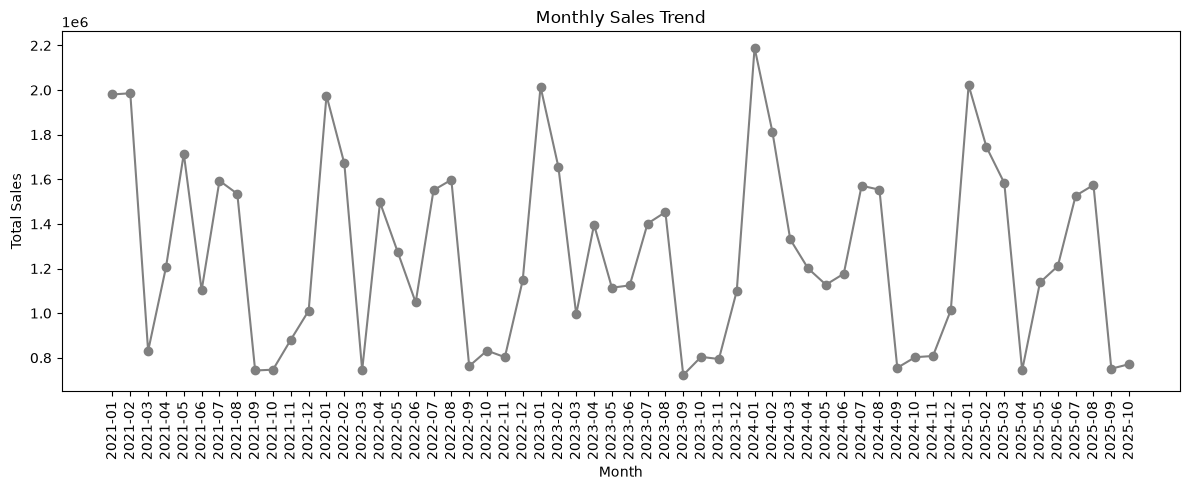

In [37]:
monthly_sales=df.groupby(df['date'].dt.to_period('M'))['total_value'].sum()
monthly_sales.index=monthly_sales.index.astype(str)

# Visualization
plt.figure(figsize=(12,5))
plt.plot(monthly_sales.index,monthly_sales.values,marker='o',color='grey')
plt.title("Monthly Sales Trend")
plt.xlabel('Month')
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**2. Which Sales generate the Highest Sales and Profit ?**

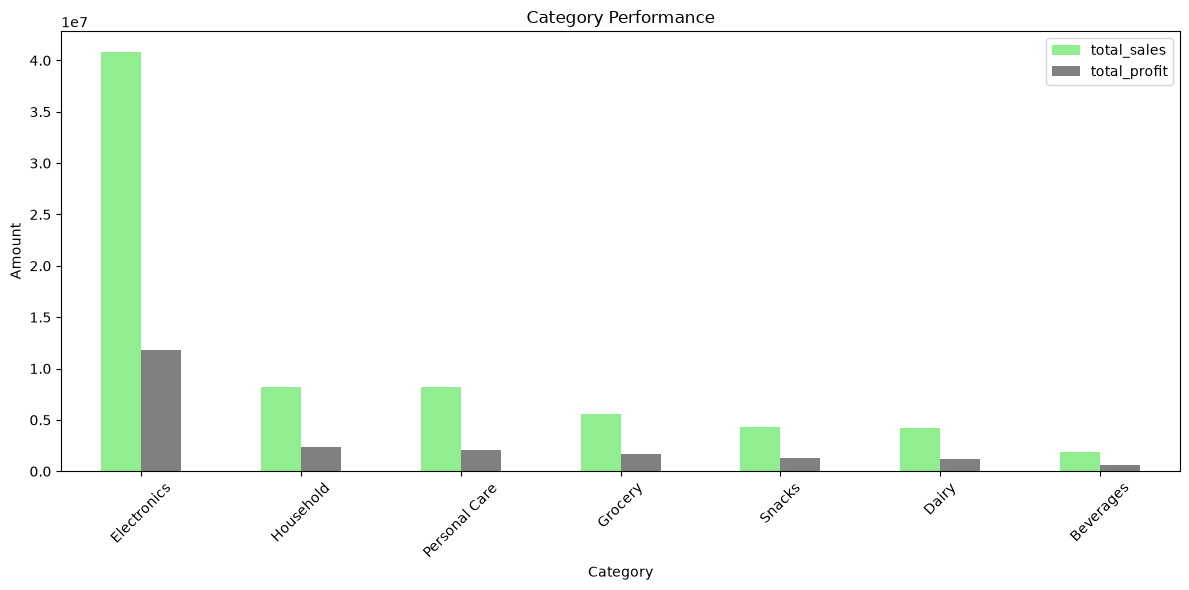

In [38]:
## Profit=total value-quantity*unitprice
df['profit']=df['total_value']-(df['quantity']*df['cost_price'])
category_performance=df.groupby('category').agg(total_sales=('total_value','sum'),total_proft=('profit','sum')).sort_values('total_sales',ascending=False)
category_performance

## Visualization
category_performance = category_performance.rename(
    columns={'total_proft': 'total_profit'}
)
category_performance[['total_sales', 'total_profit']].plot(
    kind='bar',color=['lightgreen','grey'],
    figsize=(12, 6)
)
plt.title('Category Performance')
plt.xlabel('Category')
plt.ylabel('Amount')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**3.Which products are most profitable ?**

In [39]:
product_perfo=df.groupby('subcategory').agg(total_sales=('total_value','sum'),total_profit=('profit','sum')).sort_values('total_sales',ascending=False)
product_perfo
top10_profitable=product_perfo.head(10)
top10_profitable

,total_sales,total_profit
subcategory,,
Batteries,12530863.56,3961439.04
Cables,11490862.59,3393750.71
Chargers,9227916.96,2311019.26
Mobile Accessories,7541307.78,2182056.13
Cleaning Supplies,3138214.56,898445.37
Paper Products,2745043.37,743314.52
Skincare,2424275.35,551642.10
Toothpaste,2403497.14,655592.68
Shampoo,1763986.54,399758.31


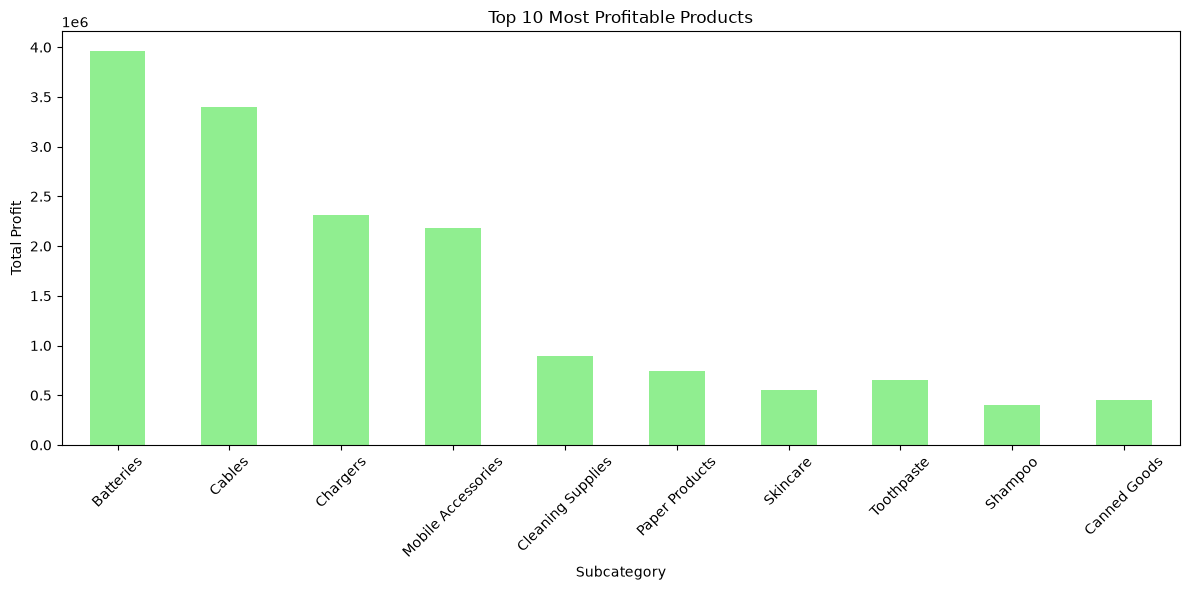

In [40]:
top10_profitable['total_profit'].plot(
    kind='bar',color='lightgreen',
    figsize=(12, 6)
)

plt.title('Top 10 Most Profitable Products')
plt.xlabel('Subcategory')
plt.ylabel('Total Profit')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**4.Which citites and stores are performing best ?**

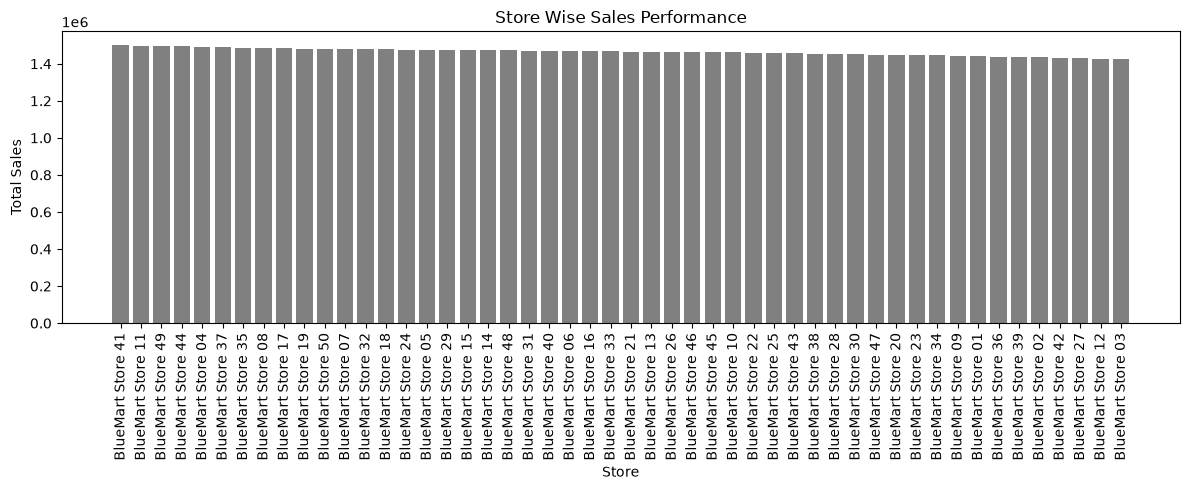

In [41]:
store_perf=df.groupby('store_name')['total_value'].sum().sort_values(ascending=False)
store_perf.head(10)

plt.figure(figsize=(12,5))
plt.bar(store_perf.index,store_perf.values,color='gray')
plt.xlabel('Store')
plt.ylabel('Total Sales')
plt.title('Store Wise Sales Performance')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

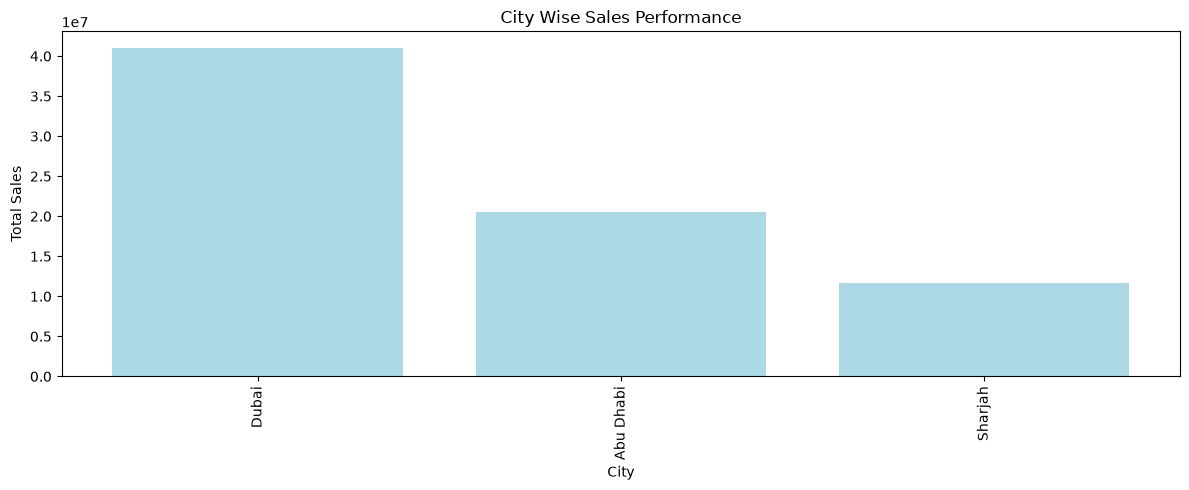

In [42]:
city_perfo=df.groupby('city')['total_value'].sum().sort_values(ascending=False)
plt.figure(figsize=(12,5))
plt.bar(city_perfo.index,city_perfo.values,color='lightblue')
plt.xlabel('City')
plt.ylabel("Total Sales")
plt.title("City Wise Sales Performance")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**5.Which Sales Channel contributes the  most revenue ?**

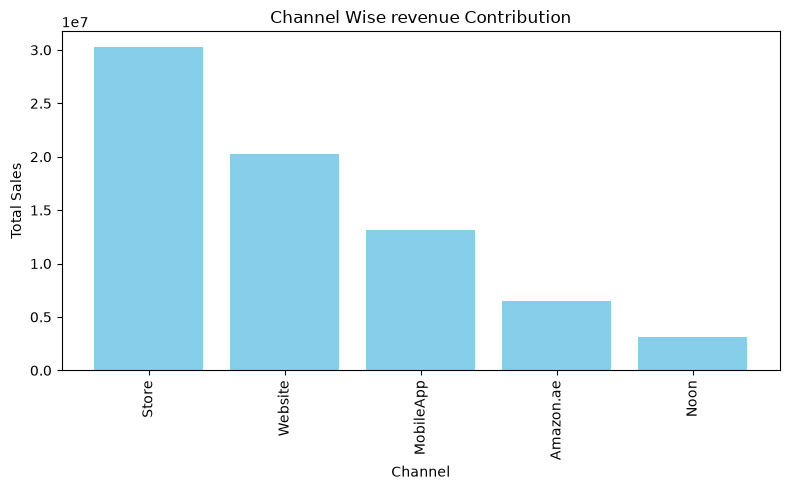

In [43]:
chan_perfo=df.groupby('channel')['total_value'].sum().sort_values(ascending=False)
chan_perfo
plt.figure(figsize=(8,5))
plt.bar(chan_perfo.index,chan_perfo.values,color='skyblue')
plt.xlabel('Channel')
plt.ylabel('Total Sales')
plt.title('Channel Wise revenue Contribution')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Ad-Hoc Analysis

In [44]:
idf=pd.read_csv(r"E:\Blue Mart Project\bm_inventory.csv")
idf.head()

,store_id,sku_id,stock_on_hand,reorder_point,safety_stock,last_restock_date,snapshot_date
0,9,1101,300,92,46,2025-10-18,2025-10-31
1,9,1021,425,162,81,2025-10-21,2025-10-31
2,9,1200,252,85,42,2025-09-14,2025-10-31
3,9,1041,220,87,43,2025-10-13,2025-10-31
4,9,1092,170,80,40,2025-09-12,2025-10-31


In [45]:
idf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8735 entries, 0 to 8734
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   store_id           8735 non-null   int64 
 1   sku_id             8735 non-null   int64 
 2   stock_on_hand      8735 non-null   int64 
 3   reorder_point      8735 non-null   int64 
 4   safety_stock       8735 non-null   int64 
 5   last_restock_date  8735 non-null   object
 6   snapshot_date      8735 non-null   object
dtypes: int64(5), object(2)
memory usage: 477.8+ KB


**Ad-Hoc 1.Which high-selling products are at risk (Out of stock)?** 

In [51]:
product_sales=df.groupby('sku_id')['quantity'].sum().reset_index()
product_sales

,sku_id,quantity
0,1001,8545
1,1002,8445
2,1003,8388
3,1004,8301
4,1005,8563
...,...,...
195,1196,8621
196,1197,8358
197,1198,8322
198,1199,8283


In [52]:
risk_df=product_sales.merge(idf,on='sku_id',how='left')
risk_df

,sku_id,quantity,store_id,stock_on_hand,reorder_point,safety_stock,last_restock_date,snapshot_date
0,1001,8545,9,88,40,20,2025-09-26,2025-10-31
1,1001,8545,10,196,68,34,2025-09-06,2025-10-31
2,1001,8545,11,111,52,26,2025-10-29,2025-10-31
3,1001,8545,12,200,71,35,2025-10-17,2025-10-31
4,1001,8545,13,62,25,12,2025-09-05,2025-10-31
...,...,...,...,...,...,...,...,...
8730,1200,8181,46,124,56,28,2025-10-16,2025-10-31
8731,1200,8181,7,229,84,42,2025-10-03,2025-10-31
8732,1200,8181,48,225,80,40,2025-09-04,2025-10-31
8733,1200,8181,49,348,165,82,2025-08-06,2025-10-31


In [63]:
risk_df['quantity'].median()
risk_df['stock_on_hand'].median()

np.float64(156.0)

In [60]:
high_sales_low_quantity=risk_df[(risk_df['quantity']>risk_df['quantity'].median()) & (risk_df['stock_on_hand']<risk_df['stock_on_hand'].median())]
high_sales_low_quantity

,sku_id,quantity,store_id,stock_on_hand,reorder_point,safety_stock,last_restock_date,snapshot_date
0,1001,8545,9,88,40,20,2025-09-26,2025-10-31
2,1001,8545,11,111,52,26,2025-10-29,2025-10-31
4,1001,8545,13,62,25,12,2025-09-05,2025-10-31
6,1001,8545,15,85,31,15,2025-08-14,2025-10-31
7,1001,8545,16,141,43,21,2025-10-13,2025-10-31
...,...,...,...,...,...,...,...,...
8532,1196,8621,1,144,45,22,2025-09-01,2025-10-31
8534,1196,8621,27,144,64,32,2025-09-14,2025-10-31
8544,1196,8621,4,139,61,30,2025-09-09,2025-10-31
8549,1196,8621,40,122,53,26,2025-09-08,2025-10-31


**Ad-Hoc 2.Which Products are below their re-order point?**

In [64]:
low_stock=idf[idf['stock_on_hand']<idf['reorder_point']]
low_stock

,store_id,sku_id,stock_on_hand,reorder_point,safety_stock,last_restock_date,snapshot_date


**Ad-Hoc 3.Which product have high sales but low profit ?**

In [65]:
product_summary=df.groupby('sku_name').agg(total_sales=('total_value','sum'),total_profit=('profit','sum'))
product_summary

,total_sales,total_profit
sku_name,,
Beverages_Coffee_1006,96824.87,16523.67
Beverages_Coffee_1141,67713.90,15553.05
Beverages_Juices_1004,192823.87,46892.29
Beverages_Juices_1012,108914.42,43695.73
Beverages_Juices_1020,76798.25,18193.53
...,...,...
Snacks_Nuts_1081,81668.99,18086.61
Snacks_Nuts_1111,103005.40,19404.70
Snacks_Nuts_1130,133901.03,34691.11


In [68]:
high_sales_low_profit=product_summary.loc[(product_summary['total_sales']>product_summary['total_sales'].median()) & (product_summary['total_profit']<product_summary['total_profit'].median())]
high_sales_low_profit

,total_sales,total_profit
sku_name,,
Dairy_Cream_1015,216990.20,53024.38
Grocery_Canned Goods_1029,221385.97,53295.53
Grocery_Pasta_1196,240533.99,56561.85
Grocery_Rice_1121,252178.55,36236.60
Grocery_Spices_1128,210567.09,53687.09
Household_Cleaning Supplies_1179,225473.13,59049.43
Household_Paper Products_1028,321556.41,58348.01
Personal Care_Soap_1156,279936.17,53765.73
